In [127]:
# load ../data/channel_data.txt as csv lat, long, height

import pandas as pd

df = pd.read_csv(
    "../data/channel_data.txt",
    header=None,
    names=["lat", "long", "height"],
    sep="\t",
)
init_lat, init_long, init_height = df.values[0]

# add init points on top of df


In [128]:
lat1 = 91
long1 = 40
lat2 = 1
long2 = 40
vector_cosine = (lat1 * lat2 + long1 * long2) / (
    np.sqrt(lat1**2 + long1**2) * np.sqrt(lat2**2 + long2**2)
)
np.arccos(vector_cosine)

np.float64(1.1316629826997648)

In [129]:
lat1 = np.radians(lat1)
long1 = np.radians(long1)
lat2 = np.radians(lat2)
long2 = np.radians(long2)

phi = lat2 - lat1
lam = long2 - long1
hav_theta = hav(phi) + np.cos(lat1) * np.cos(lat2) * hav(lam)
theta = 2 * np.arcsin(np.sqrt(hav_theta))
theta

np.float64(1.5707963267948963)

In [130]:
import numpy as np


def hav(angle):
    return (1 - np.cos(angle)) / 2


def get_distance(lat1, long1, lat2, long2):
    R = 6371
    lat1 = np.radians(lat1)
    long1 = np.radians(long1)
    lat2 = np.radians(lat2)
    long2 = np.radians(long2)

    phi = lat2 - lat1
    lam = long2 - long1
    hav_theta = hav(phi) + np.cos(lat1) * np.cos(lat2) * hav(lam)
    theta = 2 * np.arcsin(np.sqrt(hav_theta))

    distance = R * theta
    return distance * 1000

SHould i do it somehow differently, using haversine formula or whatever? I don't think so?

In [131]:
# apply along axis
df["distance"] = df.apply(
    lambda row: get_distance(init_lat, init_long, row["lat"], row["long"]), axis=1
)
df

,lat,long,height,distance
0,31.096216,27.941447,0,0.000000
1,31.078225,27.942138,19,2001.580024
2,31.069844,27.941955,22,2932.779880
3,31.062198,27.941269,23,3782.627105
4,31.055140,27.940582,22,4568.200046
...,...,...,...,...
94,30.447934,28.014740,214,72424.995652
95,30.438462,28.013366,134,73460.976148
96,30.427805,28.012680,7,74634.859565
97,30.420108,28.012680,49,75487.253103


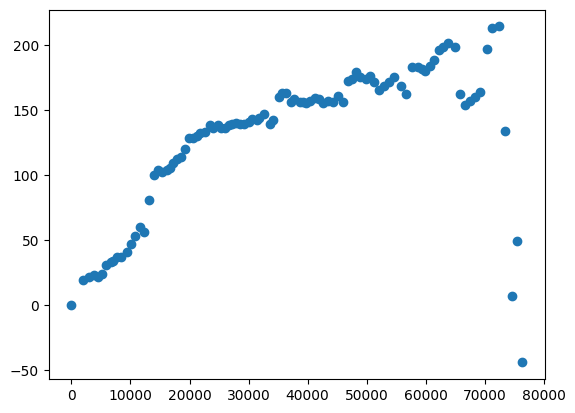

In [132]:
import matplotlib.pyplot as plt


plt.figure()

plt.scatter(df["distance"], df["height"])

plt.show()

In [133]:
df["angle"] = (df["height"].shift(-1) - df["height"]) / (
    df["distance"].shift(-1) - df["distance"]
)

max_distance = df["distance"].max()
interpolated_heights = []
distances = []

curr_distance = 0
last_ref_distance_index = 0
while curr_distance < max_distance:
    distances.append(curr_distance)
    if curr_distance >= df.iloc[last_ref_distance_index + 1]["distance"]:
        last_ref_distance_index += 1

    val = df.iloc[last_ref_distance_index]["height"] + df.iloc[last_ref_distance_index][
        "angle"
    ] * (curr_distance - df.iloc[last_ref_distance_index]["distance"])

    curr_distance += 250
    interpolated_heights.append(val)

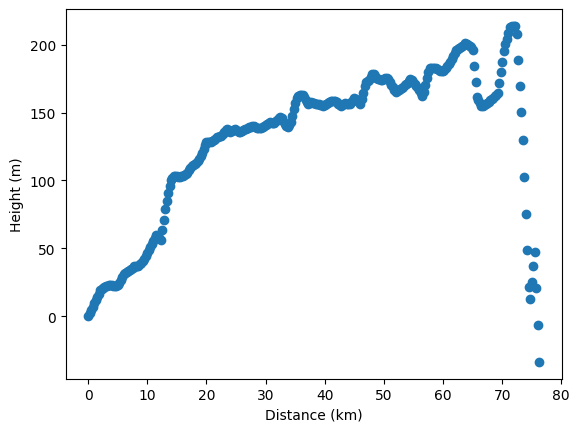

In [134]:
plt.figure()
plt.scatter(np.array(distances) / 1000, interpolated_heights)
plt.xlabel("Distance (km)")
plt.ylabel("Height (m)")
plt.show()

In [135]:
# save distances and interpolated_heights to csv

# Save as tab-separated values (TSV)
np.savetxt(
    "../data/interpolated_heights.txt",
    np.column_stack([distances, interpolated_heights]),
    delimiter="\t",
    header="distance\theight",
    comments="",
)

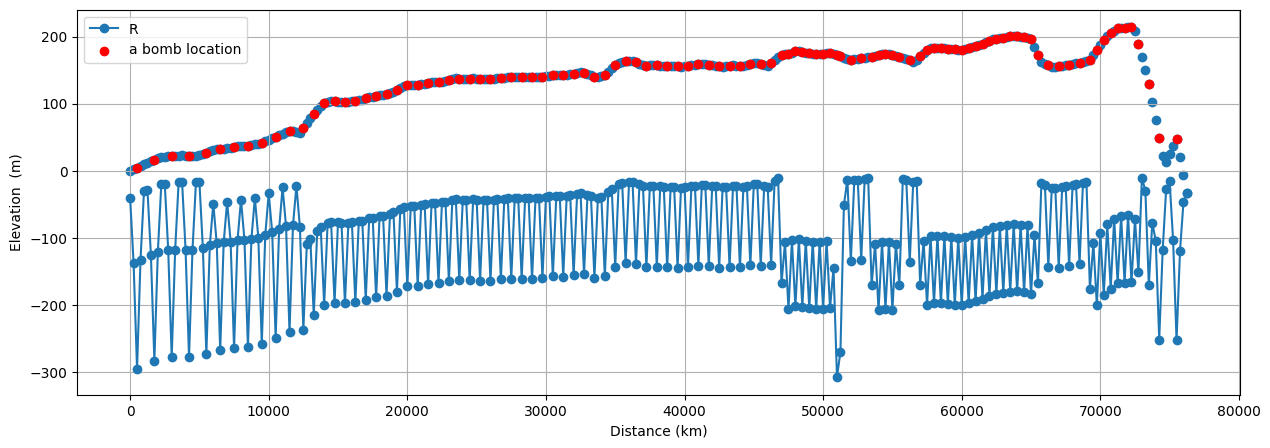

In [136]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("../data/solution_results.txt", sep="\t")

plt.figure(figsize=(15, 5))
plt.plot(
    results["distance"], interpolated_heights - results["R"], label="R", marker="o"
)

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(interpolated_heights)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="red",
    label="a bomb location",
    zorder=5,
)
plt.scatter(distances, interpolated_heights)
plt.xlabel("Distance (km)")
plt.ylabel("Elevation  (m)")
# plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

In [137]:
# count how many bombs were placed
num_bombs = results["x"].sum()
print(f"Number of bombs placed: {num_bombs}")

Number of bombs placed: 108.0


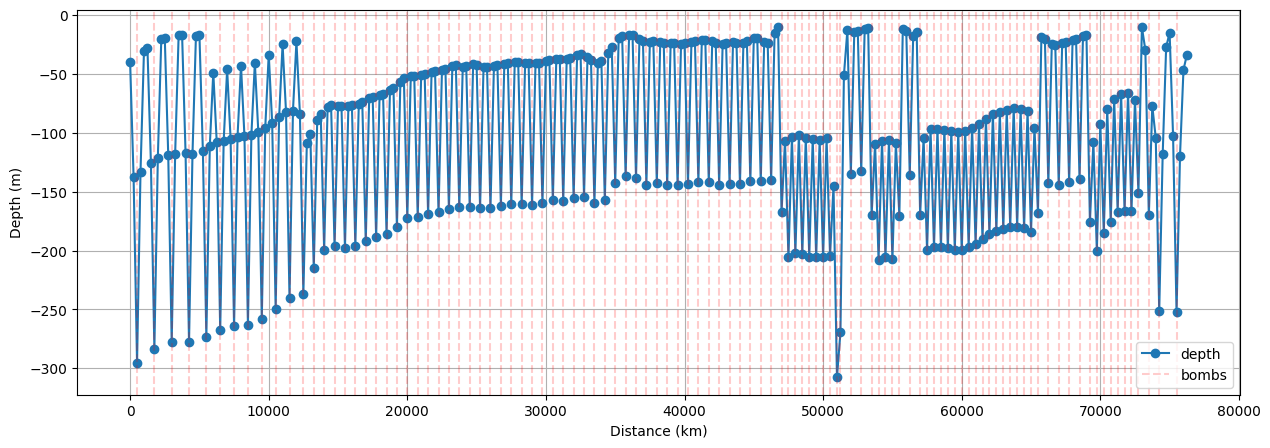

Number of bombs placed: 108.0


In [138]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt


results = pd.read_csv("../data/solution_results.txt", sep="\t")
num_bombs = results["x"].sum()
depth = interpolated_heights - results["R"]  # R is removed dirt
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]

plt.figure(figsize=(15, 5))

plt.plot(results["distance"], depth, label="depth", marker="o")

for x in selected["distance"]:
    plt.axvline(x, color="red", alpha=0.2, linestyle="--", label="bombs")

# Avoid duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.grid(True)

plt.xlabel("Distance (km)")
plt.ylabel("Depth (m)")
plt.show()

num_bombs = results["x"].sum()
print(f"Number of bombs placed: {num_bombs}")

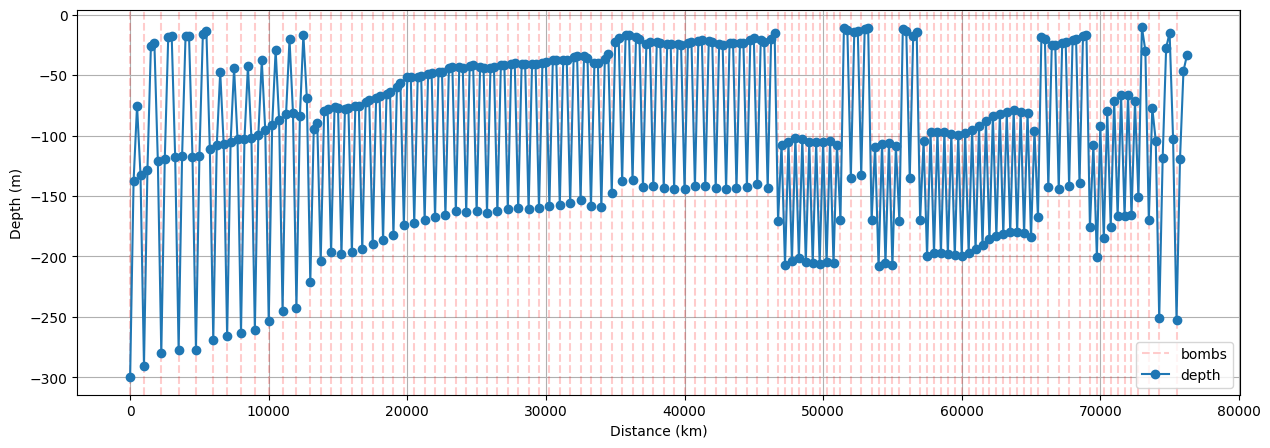

Number of bombs placed: 108.0


In [139]:
plt.figure(figsize=(15, 5))

results = pd.read_csv("../data/smooth_solution_results.txt", sep="\t")
num_bombs = results["x"].sum()
depth = interpolated_heights - results["R"]  # R is removed dirt

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(depth)[results["x"] == 1]
for x in selected["distance"]:
    plt.axvline(x, color="red", alpha=0.2, linestyle="--", label="bombs")

plt.plot(results["distance"], depth, label="depth", marker="o")
# Avoid duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
# plt.scatter(distances, interpolated_heights)

plt.legend(by_label.values(), by_label.keys())

plt.xlabel("Distance (km)")
plt.ylabel("Depth (m)")
plt.grid(True)
plt.show()

print(f"Number of bombs placed: {num_bombs}")

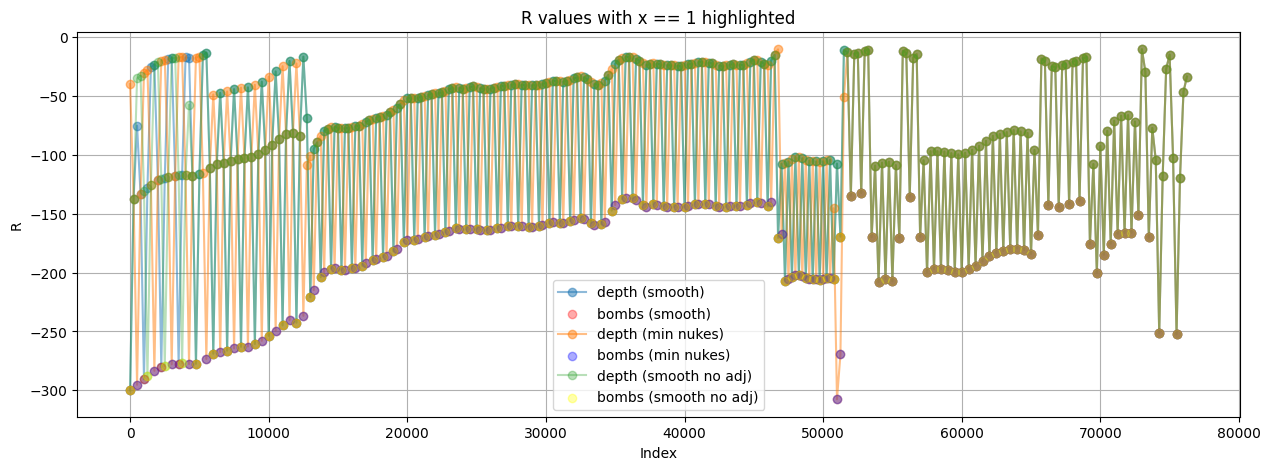

In [140]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt


plt.figure(figsize=(15, 5))
results = pd.read_csv("../data/smooth_solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(results["distance"], depth, label="depth (smooth)", marker="o", alpha=0.5)

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="red",
    label="bombs (smooth)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.33,
)
# plt.scatter(distances, interpolated_heights)
results = pd.read_csv("../data/solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(results["distance"], depth, label="depth (min nukes)", marker="o", alpha=0.5)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="blue",
    label="bombs (min nukes)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.33,
)

results = pd.read_csv("../data/smooth_no_adj_solution_results.txt", sep="\t")
depth = interpolated_heights - results["R"]  # R is removed dirt
plt.plot(
    results["distance"], depth, label="depth (smooth no adj)", marker="o", alpha=0.33
)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
plt.scatter(
    selected["distance"],
    selected_heights,
    color="yellow",
    label="bombs (smooth no adj)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.33,
)


plt.xlabel("Index")
plt.ylabel("R")
plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

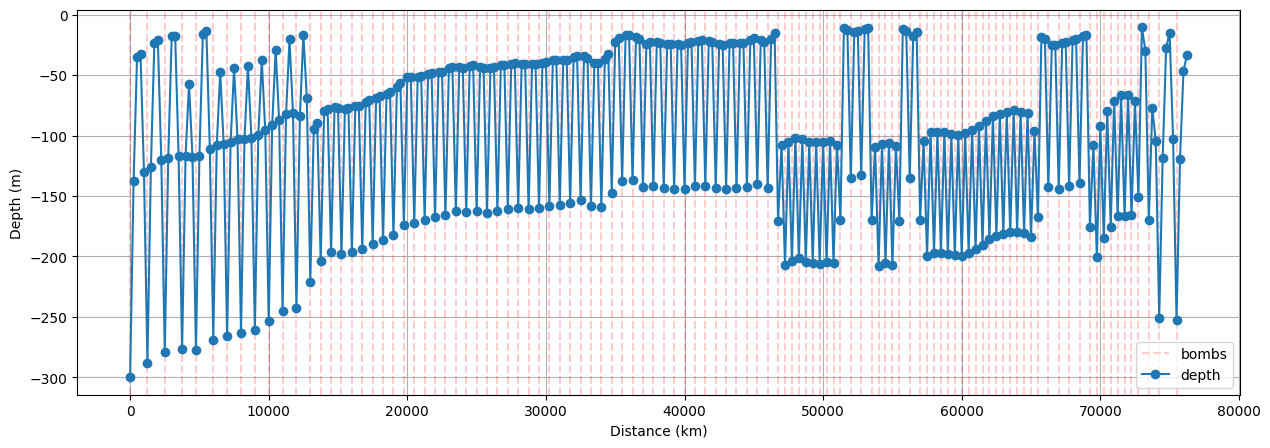

Number of bombs placed: 108.0


In [141]:
plt.figure(figsize=(15, 5))

results = pd.read_csv("../data/smooth_no_adj_solution_results.txt", sep="\t")
num_bombs = results["x"].sum()
depth = interpolated_heights - results["R"]  # R is removed dirt

# Mark where x == 1
selected = results[results["x"] == 1]

selected_heights = np.array(depth)[results["x"] == 1]
for x in selected["distance"]:
    plt.axvline(x, color="red", alpha=0.2, linestyle="--", label="bombs")

plt.plot(results["distance"], depth, label="depth", marker="o")
# Avoid duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
# plt.scatter(distances, interpolated_heights)

plt.legend(by_label.values(), by_label.keys())

plt.xlabel("Distance (km)")
plt.ylabel("Depth (m)")
plt.grid(True)
plt.show()

print(f"Number of bombs placed: {num_bombs}")

### Dial a yield - is it worth it?

In [142]:
# below is only for the first 250 entries, otherwise solver runs >10 min.

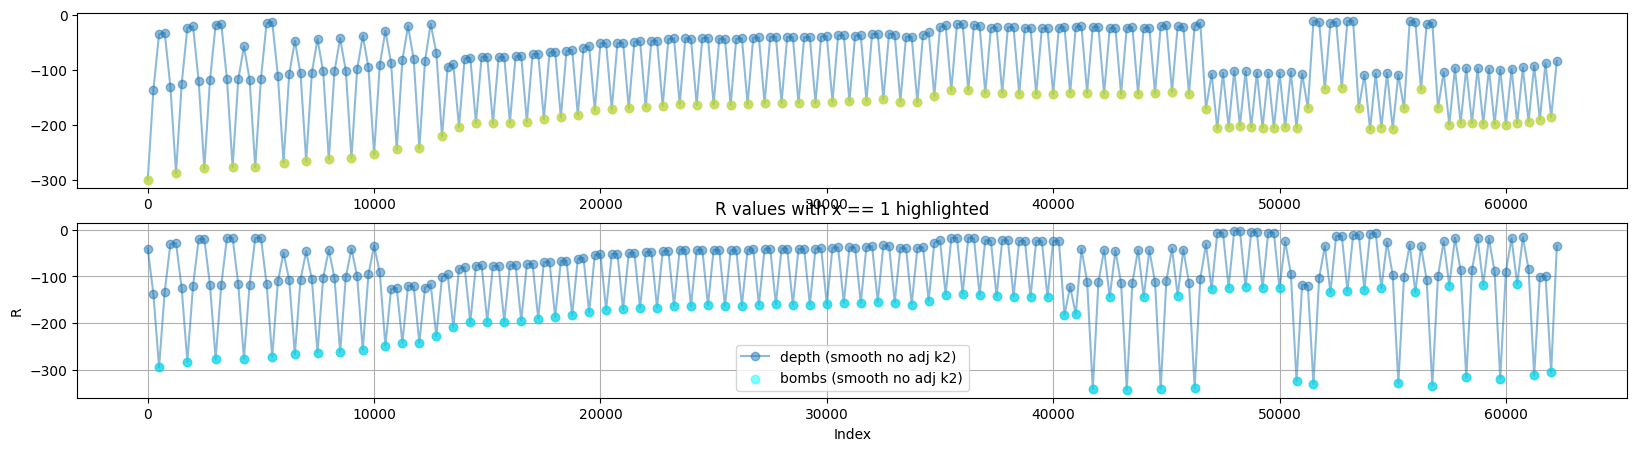

In [143]:
# Load the results from Julia and plot
import pandas as pd
import matplotlib.pyplot as plt

entries = 250


# plt.figure(figsize=(15, 5))
# subplots
fig, axs = plt.subplots(2, 1, figsize=(20, 5))

results = pd.read_csv("../data/smooth_no_adj_solution_results.txt", sep="\t")
results = results[:entries]
ih = np.array(interpolated_heights)[:entries]
depth = ih - results["R"]  # R is removed dirt
axs[0].plot(
    results["distance"], depth, label="depth (smooth no adj)", marker="o", alpha=0.5
)
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
axs[0].scatter(
    selected["distance"],
    selected_heights,
    color="yellow",
    label="bombs (smooth no adj)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.5,
)

results = pd.read_csv(
    "../data/smooth_no_adj_dial_k2_solution_results_250.txt", sep="\t"
)
# results = results[:entries]
ih = np.array(interpolated_heights)[:entries]
depth = ih - results["R"]  # R is removed dirt
axs[1].plot(
    results["distance"], depth, label="depth (smooth no adj k2)", marker="o", alpha=0.5
)
selected = results[(results["x1"] == 1) | (results["x2"] == 1)]
selected_heights = np.array(depth)[(results["x1"] == 1) | (results["x2"] == 1)]
axs[1].scatter(
    selected["distance"],
    selected_heights,
    color="cyan",
    label="bombs (smooth no adj k2)",
    zorder=5,
    # set opacity to 0.5
    alpha=0.5,
)


plt.xlabel("Index")
plt.ylabel("R")
plt.title("R values with x == 1 highlighted")
plt.legend()
plt.grid(True)
plt.show()

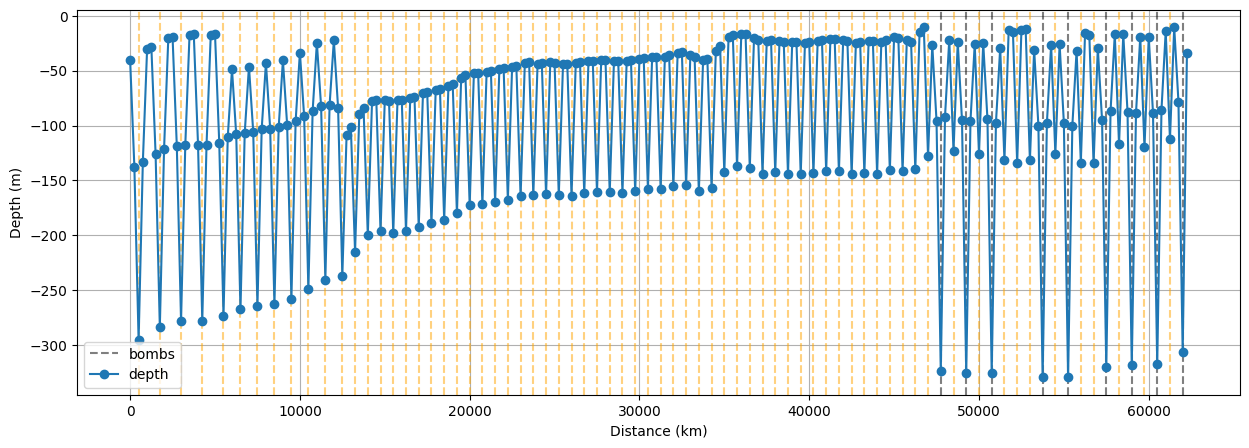

Number of bombs placed: 78.0


In [157]:
plt.figure(figsize=(15, 5))

results = pd.read_csv("../data/smooth_no_adj_dial_solution_results.txt", sep="\t")
num_bombs = results["x1"].sum() + results["x2"].sum() + results["x3"].sum()
depth = interpolated_heights[:250] - results["R"]  # R is removed dirt

# Mark where x == 1
selected = results[results["x1"] == 1]
selected_heights = np.array(depth)[results["x1"] == 1]
for x in selected["distance"]:
    plt.axvline(x, color="orange", alpha=0.5, linestyle="--", label="bombs")
selected = results[results["x2"] == 1]
selected_heights = np.array(depth)[results["x2"] == 1]
for x in selected["distance"]:
    plt.axvline(x, color="black", alpha=0.5, linestyle="--", label="bombs")
selected = results[results["x3"] == 1]
selected_heights = np.array(depth)[results["x3"] == 1]
for x in selected["distance"]:
    plt.axvline(x, color="blue", alpha=0.3, linestyle="--", label="bombs")

plt.plot(results["distance"], depth, label="depth", marker="o")
# Avoid duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
# plt.scatter(distances, interpolated_heights)

plt.legend(by_label.values(), by_label.keys())

plt.xlabel("Distance (km)")
plt.ylabel("Depth (m)")
plt.grid(True)
plt.show()

print(f"Number of bombs placed: {num_bombs}")

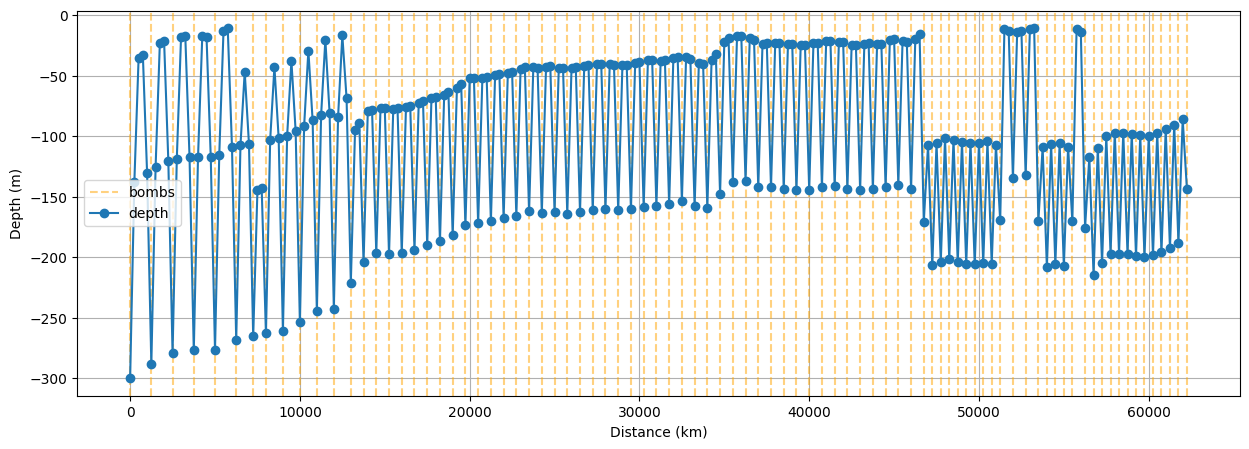

Number of bombs placed: 87.0


In [160]:
plt.figure(figsize=(15, 5))

results = pd.read_csv("../data/smooth_no_adj_solution_results_250.txt", sep="\t")
num_bombs = results["x"].sum()
depth = interpolated_heights[:250] - results["R"]  # R is removed dirt

# Mark where x == 1
selected = results[results["x"] == 1]
selected_heights = np.array(depth)[results["x"] == 1]
for x in selected["distance"]:
    plt.axvline(x, color="orange", alpha=0.5, linestyle="--", label="bombs")

plt.plot(results["distance"], depth, label="depth", marker="o")
# Avoid duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
# plt.scatter(distances, interpolated_heights)

plt.legend(by_label.values(), by_label.keys())

plt.xlabel("Distance (km)")
plt.ylabel("Depth (m)")
plt.grid(True)
plt.show()

print(f"Number of bombs placed: {num_bombs}")